# Visualizing Data & Communicating Insights
## Breast Cancer Diagnostic Data: what separates malignant from benign tumours?

**Goal:** turn data into clear visual stories. Each chart below answers one question, and is followed by what it shows and what it could mean in the real world.

**Dataset:** Breast Cancer Wisconsin (Diagnostic), bundled with Scikit-learn. 569 patients, 30 measurements of cell nuclei taken from a digitised image of a fine needle aspirate of a breast mass, plus the diagnosis (malignant or benign). Features describe each nucleus: size (radius, perimeter, area), shape (concavity, concave points, symmetry) and texture.

**Business context:** a screening team wants to know which measurements are most useful for flagging suspicious cases, so that attention and follow-up tests go where they matter most.

## 1. Setup and data loading

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100

# Works inside the repo (notebooks/ folder) and in Google Colab
ROOT = ".." if os.path.basename(os.getcwd()) == "notebooks" else "."
IMG_DIR = f"{ROOT}/images"
os.makedirs(IMG_DIR, exist_ok=True)

def save_fig(name):
    """Save the current figure to images/ and show it."""
    plt.tight_layout()
    plt.savefig(f"{IMG_DIR}/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

# One colour per diagnosis, used in every chart so the story stays consistent
PALETTE = {"Benign": "#2a7fbf", "Malignant": "#d6432f"}

In [2]:
data = load_breast_cancer(as_frame=True)
df = data.frame.copy()

# In Scikit-learn, target 0 = malignant and 1 = benign. Make the labels readable.
df["diagnosis"] = df["target"].map({0: "Malignant", 1: "Benign"})
df["is_malignant"] = (df["target"] == 0).astype(int)

print("Rows, columns:", df.shape)
print("Missing values:", int(df.isna().sum().sum()))
df[["mean radius", "mean area", "mean concavity", "mean texture", "diagnosis"]].head()

Rows, columns: (569, 33)
Missing values: 0


,mean radius,mean area,mean concavity,mean texture,diagnosis
0,17.99,1001.0,0.3001,10.38,Malignant
1,20.57,1326.0,0.0869,17.77,Malignant
2,19.69,1203.0,0.1974,21.25,Malignant
3,11.42,386.1,0.2414,20.38,Malignant
4,20.29,1297.0,0.1980,14.34,Malignant


In [3]:
df.groupby("diagnosis")[["mean radius", "mean area", "mean concavity", "mean texture", "mean smoothness"]].agg(["mean", "median"]).round(2)

mean radius        mean area        mean concavity         \
                 mean median      mean median           mean median   
diagnosis                                                             
Benign          12.15  12.20    462.79  458.4           0.05   0.04   
Malignant       17.46  17.33    978.38  932.0           0.16   0.15   

          mean texture        mean smoothness         
                  mean median            mean median  
diagnosis                                             
Benign           17.91  17.39            0.09   0.09  
Malignant        21.60  21.46            0.10   0.10

## 2. Visualization 1: How many cases are malignant vs benign?

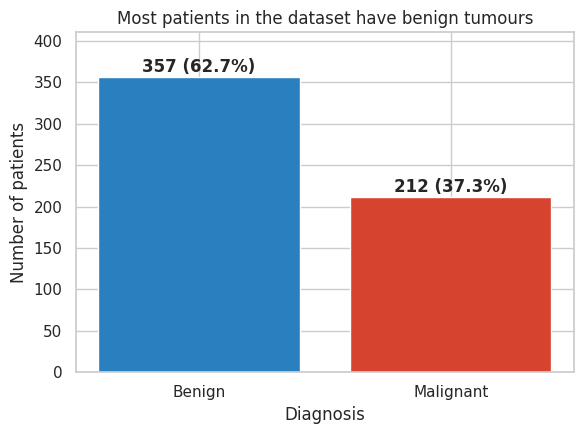

In [4]:
counts = df["diagnosis"].value_counts().reindex(["Benign", "Malignant"])
pct = counts / counts.sum() * 100

fig, ax = plt.subplots(figsize=(6, 4.5))
bars = ax.bar(counts.index, counts.values, color=[PALETTE[c] for c in counts.index])
for bar, n, p in zip(bars, counts.values, pct.values):
    ax.text(bar.get_x() + bar.get_width() / 2, n + 6, f"{n} ({p:.1f}%)", ha="center", fontweight="bold")
ax.set_title("Most patients in the dataset have benign tumours")
ax.set_xlabel("Diagnosis")
ax.set_ylabel("Number of patients")
ax.set_ylim(0, counts.max() * 1.15)
save_fig("01_diagnosis_counts")

**What it shows:** 357 benign (62.7%) and 212 malignant (37.3%) cases.

**Insight:** the data is moderately imbalanced. A model or screening rule that always said "benign" would be right 63% of the time but would miss every cancer, so accuracy alone is not enough.

**Real-world meaning:** missing a malignant case costs far more than a false alarm, so success must be judged by how many malignant cases are caught, not by overall accuracy.

## 3. Visualization 2: Are malignant nuclei larger?

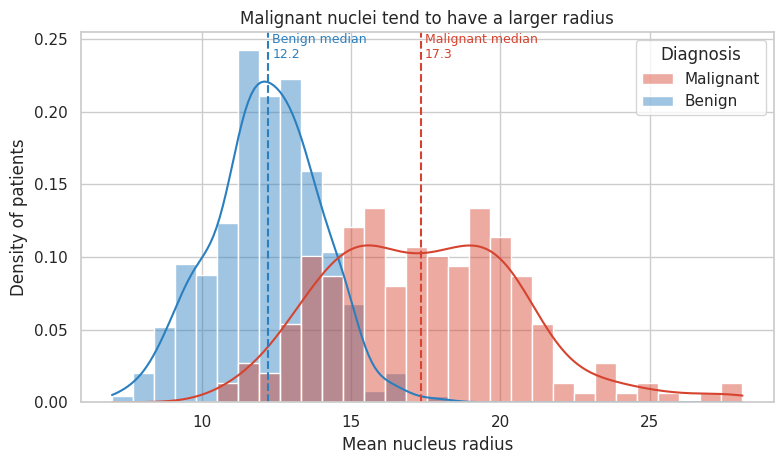

In [5]:
fig, ax = plt.subplots(figsize=(8, 4.8))
sns.histplot(data=df, x="mean radius", hue="diagnosis", palette=PALETTE, bins=30,
             kde=True, stat="density", common_norm=False, alpha=0.45, ax=ax)
for diag, colour in PALETTE.items():
    median = df.loc[df["diagnosis"] == diag, "mean radius"].median()
    ax.axvline(median, color=colour, linestyle="--", linewidth=1.5)
    ax.text(median + 0.15, ax.get_ylim()[1] * 0.93, f"{diag} median\n{median:.1f}", color=colour, fontsize=9)
ax.set_title("Malignant nuclei tend to have a larger radius")
ax.set_xlabel("Mean nucleus radius")
ax.set_ylabel("Density of patients")
ax.get_legend().set_title("Diagnosis")
save_fig("02_radius_distribution")

**What it shows:** two overlapping distributions. The benign curve is narrow and peaks near a radius of 12. The malignant curve is much broader, spread mostly between about 14 and 22.

**Insight:** the median radius is about 12.2 for benign and 17.3 for malignant cases, a clear gap. The curves overlap between roughly 11 and 16, so radius alone cannot decide every case.

**Real-world meaning:** a size threshold is a useful first filter. A very large radius is a strong warning sign, while mid-range values need other measurements.

## 4. Visualization 3: How different is nucleus area between the two groups?

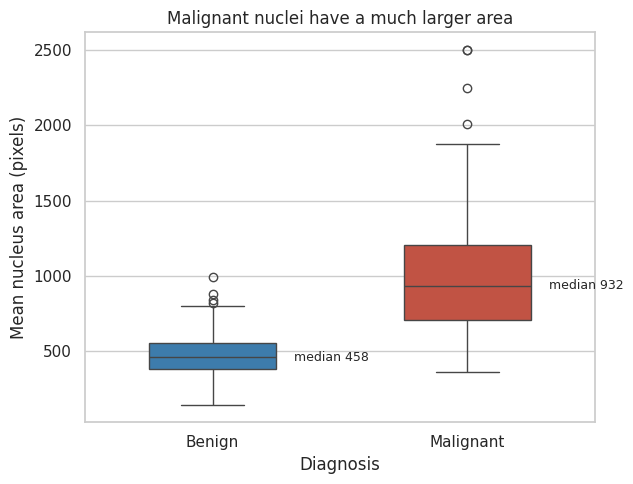

In [6]:
fig, ax = plt.subplots(figsize=(6.5, 5))
order = ["Benign", "Malignant"]
sns.boxplot(data=df, x="diagnosis", y="mean area", order=order, hue="diagnosis",
            palette=PALETTE, legend=False, width=0.5, ax=ax)
for i, diag in enumerate(order):
    median = df.loc[df["diagnosis"] == diag, "mean area"].median()
    ax.text(i + 0.32, median, f"median {median:.0f}", va="center", fontsize=9)
ax.set_title("Malignant nuclei have a much larger area")
ax.set_xlabel("Diagnosis")
ax.set_ylabel("Mean nucleus area (pixels)")
save_fig("03_area_boxplot")

**What it shows:** a box plot of nucleus area for each diagnosis. The box is the middle 50% of patients and the line is the median.

**Insight:** the median area is about 458 for benign and 932 for malignant, roughly double. Malignant cases also vary far more, with a long tail of very large values.

**Real-world meaning:** unusually large and variable nuclei are a hallmark of abnormal cell growth, which matches what the chart shows.

## 5. Visualization 4: Do size and shape together separate the groups better?

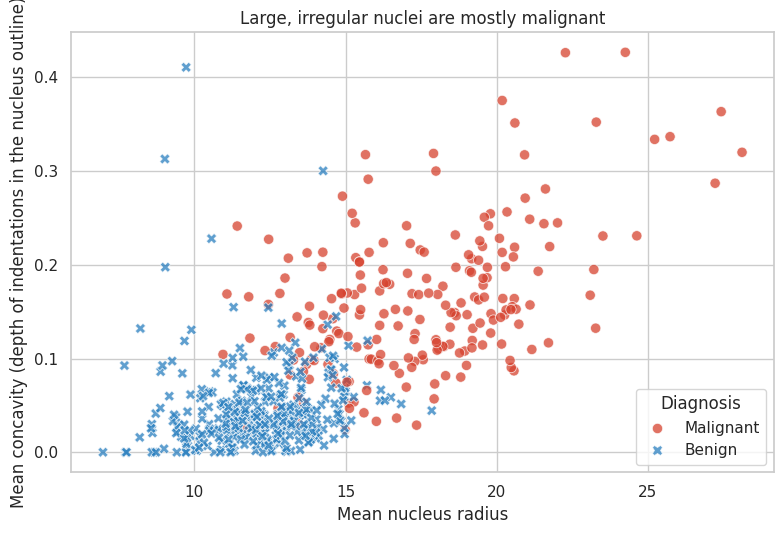

In [7]:
fig, ax = plt.subplots(figsize=(8, 5.5))
sns.scatterplot(data=df, x="mean radius", y="mean concavity", hue="diagnosis",
                palette=PALETTE, style="diagnosis", s=55, alpha=0.75, ax=ax)
ax.set_title("Large, irregular nuclei are mostly malignant")
ax.set_xlabel("Mean nucleus radius")
ax.set_ylabel("Mean concavity (depth of indentations in the nucleus outline)")
ax.legend(title="Diagnosis", loc="lower right")
save_fig("04_radius_vs_concavity")

**What it shows:** each dot is a patient. Benign cases cluster in the bottom-left (small and smooth), malignant cases spread to the top-right (large and irregular).

**Insight:** combining two features separates the groups better than radius alone: at a radius above 15 with concavity above 0.1, almost every point is malignant. A few benign cases with unusually high concavity, and malignant cases with small radius, still land in the wrong zone.

**Real-world meaning:** a two-measurement check can flag most high-risk patients, and only the cases that land in the mixed middle zone need extra review.

## 6. Visualization 5: Which measurements are most linked to malignancy?

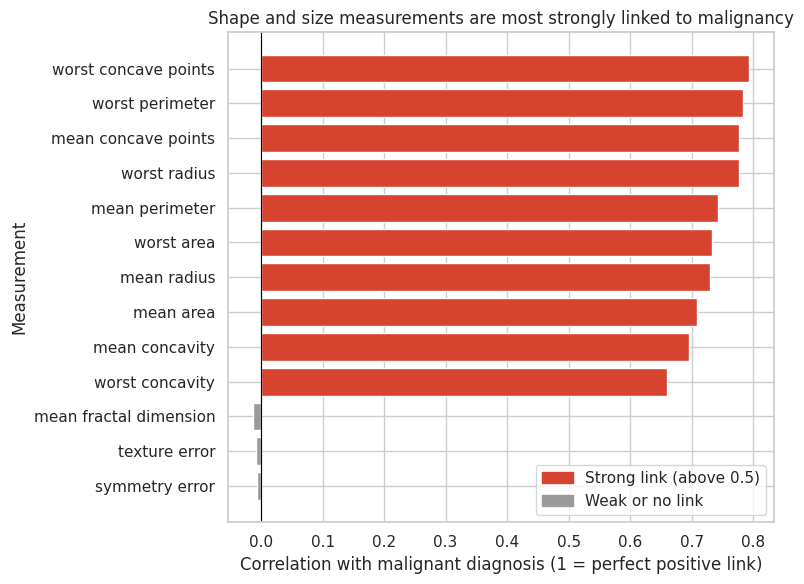

,0
worst concave points,0.794
worst perimeter,0.783
mean concave points,0.777
worst radius,0.776
mean perimeter,0.743


In [8]:
features = [c for c in data.feature_names]
corr_with_malignant = df[features].corrwith(df["is_malignant"]).sort_values()
weakest = corr_with_malignant[corr_with_malignant.abs().sort_values().index[:3]]   # 3 weakest links
strongest = corr_with_malignant.sort_values().tail(10)                             # 10 strongest links
top = pd.concat([weakest, strongest])

fig, ax = plt.subplots(figsize=(8, 6))
colours = ["#d6432f" if v > 0.5 else "#9a9a9a" for v in top.values]
ax.barh(top.index, top.values, color=colours)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Shape and size measurements are most strongly linked to malignancy")
ax.set_xlabel("Correlation with malignant diagnosis (1 = perfect positive link)")
ax.set_ylabel("Measurement")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color="#d6432f", label="Strong link (above 0.5)"),
                   Patch(color="#9a9a9a", label="Weak or no link")], loc="lower right")
save_fig("05_top_correlations")
corr_with_malignant.sort_values(ascending=False).head(5).round(3)

**What it shows:** the correlation of each measurement with a malignant diagnosis. The red bars are the strongest links, the grey bars are measurements that barely matter.

**Insight:** "worst concave points" (0.79), "worst perimeter" (0.78), "mean concave points" (0.78) and "worst radius" (0.78) lead the ranking. Symmetry error, texture error and mean fractal dimension (all near 0.01) carry almost no signal.

**Real-world meaning:** a lab could prioritise the few most informative measurements and spend less effort on the weak ones.

## 7. Visualization 6: Are the measurements telling us the same thing?

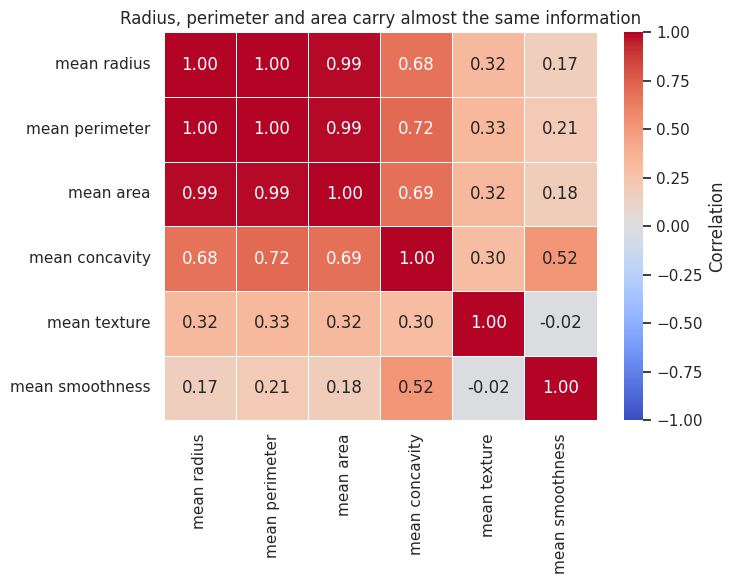

In [9]:
cols = ["mean radius", "mean perimeter", "mean area", "mean concavity", "mean texture", "mean smoothness"]

fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(df[cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            linewidths=0.5, cbar_kws={"label": "Correlation"}, ax=ax)
ax.set_title("Radius, perimeter and area carry almost the same information")
save_fig("06_correlation_heatmap")

**What it shows:** how strongly pairs of measurements move together (1 = identical pattern, 0 = unrelated).

**Insight:** radius, perimeter and area are almost perfectly linked (0.998 for radius with perimeter, 0.987 for radius with area). Texture and smoothness are only weakly linked to size.

**Real-world meaning:** measuring all three size features adds little extra information, so a simpler test with one size measure plus one shape measure can be nearly as informative.

## 8. Visualization 7: A measurement that does not separate the groups well

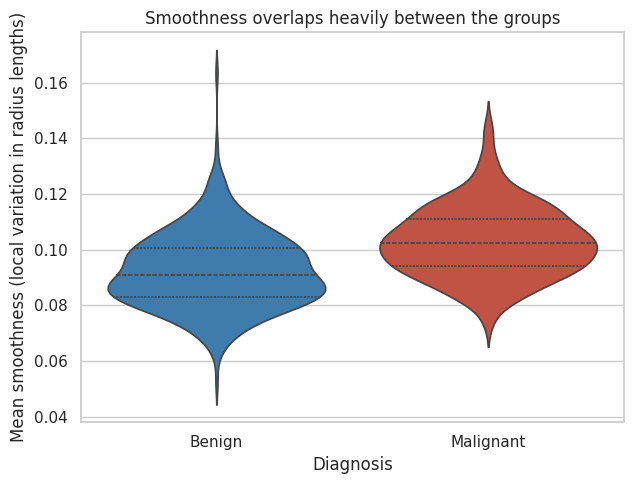

In [10]:
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.violinplot(data=df, x="diagnosis", y="mean smoothness", order=order, hue="diagnosis",
               palette=PALETTE, legend=False, inner="quartile", ax=ax)
ax.set_title("Smoothness overlaps heavily between the groups")
ax.set_xlabel("Diagnosis")
ax.set_ylabel("Mean smoothness (local variation in radius lengths)")
save_fig("07_smoothness_violin")

**What it shows:** the shape of the smoothness distribution for each diagnosis. A wider part of the violin means more patients at that value.

**Insight:** the medians are close (about 0.091 benign vs 0.102 malignant) and the shapes overlap heavily, so smoothness is a weak separator compared with size or concave points.

**Real-world meaning:** not every measurement is worth collecting. Charts like this help avoid giving weight to a signal that does not help.

## 9. Summary of insights

1. 37% of cases are malignant, so overall accuracy is a misleading way to judge a screening rule.
2. Malignant nuclei are larger: median area about 932 vs 458, median radius about 17.3 vs 12.2.
3. Size and shape together separate the groups far better than either one alone.
4. The most informative measurements are concave points, perimeter and radius. Symmetry error, texture error and mean fractal dimension carry almost no signal.
5. Radius, perimeter and area are redundant, so one size measure is enough.
6. Smoothness overlaps heavily and is a weak separator.

**Recommendation:** focus screening review on patients with large, irregular nuclei, use one size measure plus one shape measure as a quick first check, and send borderline cases for further testing. These are patterns in one dataset, not a diagnostic tool, and any real use would need clinical validation.